# Program 28: K-Means Clustering for Customer Segmentation

**Scenario / Problem Statement**

Segment online store customers into groups using annual spending, orders per year, and average basket value.

Run the cells from top to bottom in Google Colab.

> **Sample inputs used for this run:** in_spend = 2500, in_orders = 10, in_basket = 100. Values are labeled in the code.

## 1. Import required libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler


## 2. Upload and load the supplied dataset

Dataset loaded: FODS_Lab_Datasets_Q20_to_Q40.xlsx - Q28_Customer_Seg_KMeans.csv
Shape: (60, 4)
C:\ProgramData\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py:131: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "C:\ProgramData\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 247, in _count_physical_cores
    cpu_count_physical = _count_physical_cores_win32()
  File "C:\ProgramData\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 299, in _count_physical_cores_win32
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "C:\ProgramData\anaconda3\Lib\subprocess.py", 

,Customer_ID,Annual_Spend_USD,Orders_Per_Year,Avg_Basket_USD
0,EC-001,"$1,647.80",13,$84.18
1,EC-002,$198.40,6,$72.17
2,EC-003,"$1,376.67",20,$98.86
3,EC-004,"$1,450.81",18,$88.51
4,EC-005,"$3,072.40",23,$182.82


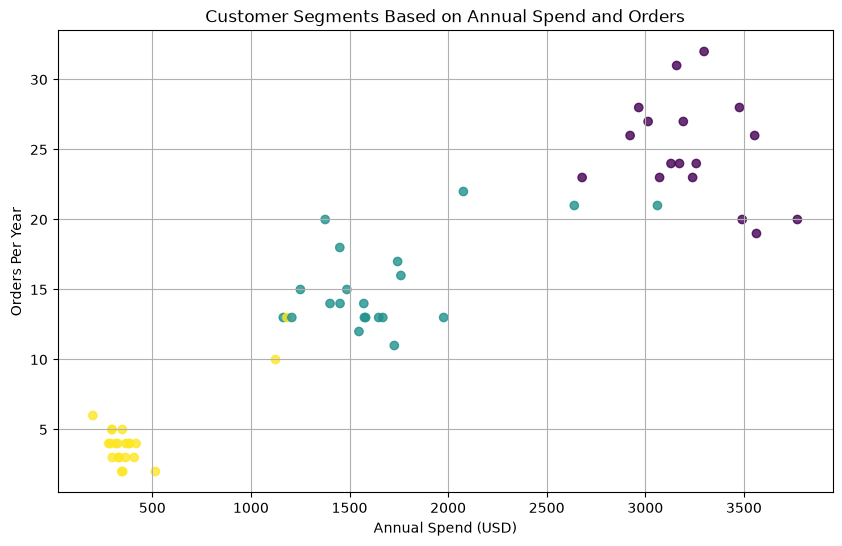

In [2]:
# Load the supplied CSV. In Colab, upload it if it is not already present.
from pathlib import Path
DATA_FILE = 'FODS_Lab_Datasets_Q20_to_Q40.xlsx - Q28_Customer_Seg_KMeans.csv'
if not Path(DATA_FILE).exists():
    try:
        from google.colab import files
        files.upload()
    except ImportError as exc:
        raise FileNotFoundError('FODS_Lab_Datasets_Q20_to_Q40.xlsx - Q28_Customer_Seg_KMeans.csv is missing; place the CSV beside this notebook.') from exc
df_raw = pd.read_csv(DATA_FILE, skiprows=3)
print("Dataset loaded:", DATA_FILE)
print("Shape:", df_raw.shape)
display(df_raw.head())

feature_cols = ["Annual_Spend_USD", "Orders_Per_Year", "Avg_Basket_USD"]
for col in feature_cols:
    df_raw[col] = pd.to_numeric(df_raw[col].astype(str).str.replace("$", "", regex=False).str.replace(",", "", regex=False), errors="coerce")
df_model = df_raw.dropna(subset=feature_cols).copy()
X = df_model[feature_cols]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
df_model["Cluster"] = kmeans.fit_predict(X_scaled)

print("Cluster centers (original feature units):")
print(pd.DataFrame(scaler.inverse_transform(kmeans.cluster_centers_), columns=feature_cols))

plt.figure(figsize=(10, 6))
plt.scatter(df_model["Annual_Spend_USD"], df_model["Orders_Per_Year"], c=df_model["Cluster"], cmap="viridis", alpha=0.8)
plt.title("Customer Segments Based on Annual Spend and Orders")
plt.xlabel("Annual Spend (USD)")
plt.ylabel("Orders Per Year")
plt.grid(True)
plt.show()

in_spend = 2500  # SAMPLE INPUT
in_orders = 10  # SAMPLE INPUT
in_basket = 100  # SAMPLE INPUT
new_customer = pd.DataFrame([[in_spend, in_orders, in_basket]], columns=feature_cols)
segment = kmeans.predict(scaler.transform(new_customer))[0]
print(f"\nAssigned Segment / Cluster: {segment}")

## 3. Result

The output above displays the analysis, model evaluation, prediction, or visualization for this program.